In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from operator import itemgetter
%matplotlib inline

In [2]:
Train_data=pd.read_csv(r'G:\第三周\data\used_car_train_20200313\used_car_train_20200313.csv',sep=' ')
Test_data=pd.read_csv(r'G:\第三周\data\used_car_testA_20200313\used_car_testA_20200313.csv',sep=' ')

In [3]:
print(Train_data.shape)
print(Test_data.shape)

(150000, 31)
(50000, 30)


In [4]:
Train_data.columns

Index(['SaleID', 'name', 'regDate', 'model', 'brand', 'bodyType', 'fuelType',
       'gearbox', 'power', 'kilometer', 'notRepairedDamage', 'regionCode',
       'seller', 'offerType', 'creatDate', 'price', 'v_0', 'v_1', 'v_2', 'v_3',
       'v_4', 'v_5', 'v_6', 'v_7', 'v_8', 'v_9', 'v_10', 'v_11', 'v_12',
       'v_13', 'v_14'],
      dtype='object')

In [10]:
# 定义基于箱线图的异常值处理函数
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def outliers_proc(data, col_name, scale=3):
    """
    用于清洗异常值，默认用箱线图（scale=3）进行清洗
    :param data: 接收 pandas 数据格式
    :param col_name: pandas 列名
    :param scale: 箱线图尺度（默认为3）
    :return: 清洗后的DataFrame
    """
    def box_plot_outliers(data_ser, box_scale):# 子函数：利用箱线图计算异常值边界
        """
        利用箱线图识别异常值
        :param data_ser: 接收 pandas.Series 数据格式
        :param box_scale: 箱线图尺度
        :return: 异常值规则和边界值
        """
        # 计算四分位距和边界
        q1 = data_ser.quantile(0.25)# 下界
        q3 = data_ser.quantile(0.75)
        iqr = box_scale * (q3 - q1)
        val_low = q1 - iqr
        val_up = q3 + iqr
        
        # 识别异常值
        rule_low = (data_ser < val_low) # 低于下界的异常值规则
        rule_up = (data_ser > val_up)
        
        return (rule_low, rule_up), (val_low, val_up)
    
    # 复制数据以避免修改原始数据
    data_n = data.copy()
    data_series = data_n[col_name]
    
    # 识别异常值
    rule, value = box_plot_outliers(data_series, box_scale=scale)
    
    # 获取异常值索引 - 修复索引问题
    low_indices = data_series.index[rule[0]]
    up_indices = data_series.index[rule[1]]
    all_indices = low_indices.union(up_indices)
    
    # 删除异常值
    print(f"删除数量: {len(all_indices)}")
    data_n = data_n.drop(all_indices)
    data_n.reset_index(drop=True, inplace=True)# 重置索引
    print(f"处理后样本数: {data_n.shape[0]}")
    
    # 打印异常值统计信息
    if len(low_indices) > 0:
        outliers_low = data.loc[low_indices, col_name]
        print("\n低于下界的异常值统计:")
        print(outliers_low.describe())
    
    if len(up_indices) > 0:
        outliers_up = data.loc[up_indices, col_name]
        print("\n高于上界的异常值统计:")
        print(outliers_up.describe())
    
    # 绘制箱线图对比
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    fig.suptitle(f'"{col_name}" 异常值处理前后对比', fontsize=16)
    
    # 原始数据箱线图
    sns.boxplot(y=data[col_name], data=data, ax=ax[0], color='skyblue')
    ax[0].set_title('处理前')
    ax[0].set_xlabel(col_name)
    
    # 处理后数据箱线图
    sns.boxplot(y=data_n[col_name], data=data_n, ax=ax[1], color='lightgreen')
    ax[1].set_title('处理后')
    ax[1].set_xlabel(col_name)
    
    plt.tight_layout()
    plt.show()
    
    return data_n

异常值会干扰模型对数据规律的学习，箱线图法是常用的异常值检测方法：通过计算数据的四分位距（IQR = Q3 - Q1），将低于Q1 - 3*IQR或高于Q3 + 3*IQR的值定义为异常值（默认scale=3）。
对power（功率）特征处理后，删除了 963 条异常值，剩余 149037 条样本。从结果看，异常值主要集中在高功率区间（最小值 376，最大值 19312），这些极端值可能是数据录入错误或特殊车辆，删除后可使数据更符合实际分布

删除数量: 963
处理后样本数: 149037

高于上界的异常值统计:
count      963.000000
mean       846.836968
std       1929.418081
min        376.000000
25%        400.000000
50%        436.000000
75%        514.000000
max      19312.000000
Name: power, dtype: float64


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16492\4074574838.py:77: UserWarning: Glyph 22788 (\N{CJK UNIFIED IDEOGRAPH-5904}) missing from current font.
  plt.tight_layout()
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16492\4074574838.py:77: UserWarning: Glyph 29702 (\N{CJK UNIFIED IDEOGRAPH-7406}) missing from current font.
  plt.tight_layout()
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16492\4074574838.py:77: UserWarning: Glyph 21069 (\N{CJK UNIFIED IDEOGRAPH-524D}) missing from current font.
  plt.tight_layout()
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16492\4074574838.py:77: UserWarning: Glyph 21518 (\N{CJK UNIFIED IDEOGRAPH-540E}) missing from current font.
  plt.tight_layout()
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16492\4074574838.py:77: UserWarning: Glyph 24322 (\N{CJK UNIFIED IDEOGRAPH-5F02}) missing from current font.
  plt.tight_layout()
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_16492\4074574838.py:77: UserWarning: Glyph 24120 (\N{CJK UNIFIED IDEOGRAPH-5E38}

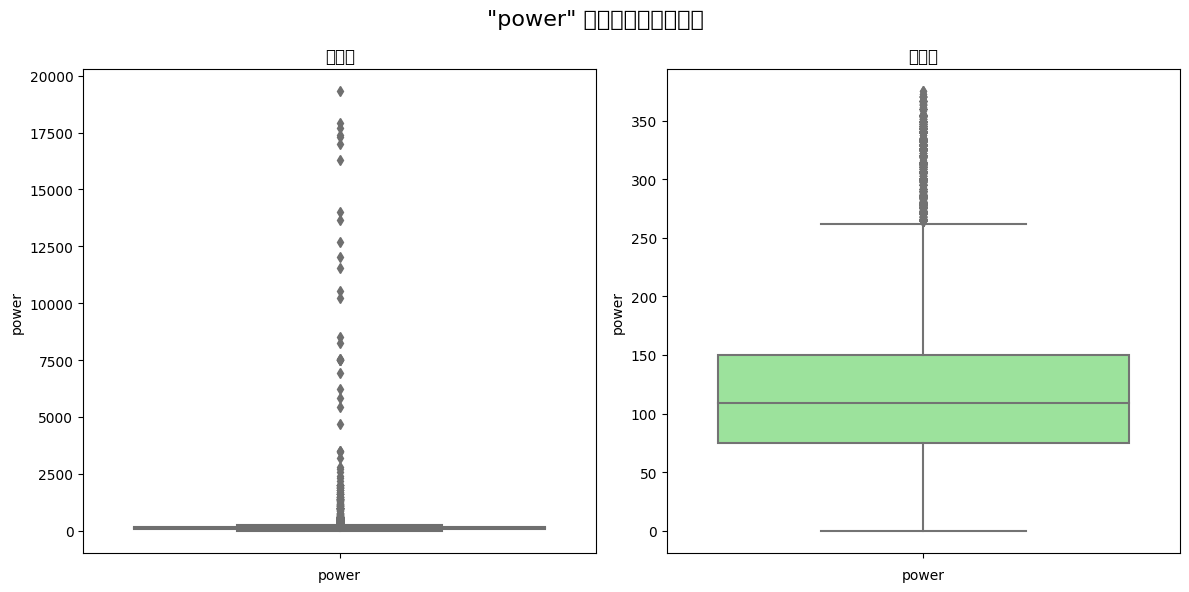

In [11]:
Train_data = outliers_proc(Train_data, 'power', scale=3)

In [13]:
# 训练集和测试集放在一起，方便构造特征
Train_data['train']=1
Test_data['train']=0
data = pd.concat([Train_data, Test_data], ignore_index=True)

In [14]:
 # 使用时间：data['creatDate'] - data['regDate']，反应汽车使用时间，一般来说价格与使用时间成反比
# 不过要注意，数据里有时间出错的格式，所以我们需要 errors='coerce'
data['used_time'] = (pd.to_datetime(data['creatDate'], format='%Y%m%d', errors='coerce') - 
                     pd.to_datetime(data['regDate'], format='%Y%m%d', errors='coerce')).dt.days

In [15]:
# 看一下空数据，有 15k 个样本的时间是有问题的，我们可以选择删除，也可以选择放着。
# 但是这里不建议删除，因为删除缺失数据占总样本量过大，7.5%
# 我们可以先放着，因为如果我们 XGBoost 之类的决策树，其本身就能处理缺失值，所以可以不用管；
data['used_time'].isnull().sum()

15072

In [16]:
# 从邮编中提取城市信息，相当于加入了先验知识
data['city'] = data['regionCode'].apply(lambda x : str(x)[:-3])
data = data

In [19]:
# 计算某品牌的销售统计量
Train_gb = Train_data.groupby("brand")
all_info = {}
for kind, kind_data in Train_gb:
    info = {}
    kind_data = kind_data[kind_data['price'] > 0]
    info['feat_brand_amount'] = len(kind_data)  # 添加前缀 feat_
    info['feat_brand_price_max'] = kind_data.price.max()
    info['feat_brand_price_median'] = kind_data.price.median()
    info['feat_brand_price_min'] = kind_data.price.min()
    info['feat_brand_price_sum'] = kind_data.price.sum()
    info['feat_brand_price_std'] = kind_data.price.std()
    info['feat_brand_price_average'] = round(kind_data.price.sum() / (len(kind_data) + 1), 2)
    all_info[kind] = info

# 创建特征DataFrame并重命名列
brand_fe = pd.DataFrame(all_info).T.reset_index().rename(columns={"index": "brand"})

# 合并到原始数据 - 现在不会有列名冲突了
Train_data = Train_data.merge(brand_fe, how='left', on='brand')

原理说明
特征构造的核心是提取数据中隐藏的有效信息，增强对目标变量（价格）的预测能力：
used_time（使用时间）：通过发布日期与注册日期的差值计算，直接反映车辆使用时长，通常与价格负相关（使用越久价格越低）。
city（城市信息）：从地区编码中提取，不同城市的二手车价格可能受地域因素（如经济水平）影响。
品牌统计特征：如brand_price_average（品牌均价）可捕捉品牌溢价（如高端品牌均价更高），brand_amount（品牌销量）反映品牌市场占有率，辅助模型判断供需关系对价格的影响。
power_bin（功率分桶）：将连续的功率特征离散化，降低异常值影响，同时使模型更易学习不同功率区间的价格规律（如中等功率车辆可能更受欢迎，价格更稳定）。

In [20]:
bin = [i*10 for i in range(31)]# 对power进行分桶（等距分桶）
data['power_bin'] = pd.cut(data['power'], bin, labels=False)
data[['power_bin', 'power']].head()# 删除无用特征

,power_bin,power
0,5.0,60
1,NaN,0
2,16.0,163
3,19.0,193
4,6.0,68


In [22]:
data = data.drop(['creatDate', 'regDate', 'regionCode'], axis=1)

In [23]:
print(data.shape)
data.columns

(199037, 53)


Index(['SaleID', 'name', 'model', 'brand', 'bodyType', 'fuelType', 'gearbox',
       'power', 'kilometer', 'notRepairedDamage', 'seller', 'offerType',
       'price', 'v_0', 'v_1', 'v_2', 'v_3', 'v_4', 'v_5', 'v_6', 'v_7', 'v_8',
       'v_9', 'v_10', 'v_11', 'v_12', 'v_13', 'v_14', 'train', 'used_time',
       'city', 'brand_amount_x', 'brand_price_average_x', 'brand_price_max_x',
       'brand_price_median_x', 'brand_price_min_x', 'brand_price_std_x',
       'brand_price_sum_x', 'brand_amount_y', 'brand_price_max_y',
       'brand_price_median_y', 'brand_price_min_y', 'brand_price_sum_y',
       'brand_price_std_y', 'brand_price_average_y', 'brand_amount',
       'brand_price_max', 'brand_price_median', 'brand_price_min',
       'brand_price_sum', 'brand_price_std', 'brand_price_average',
       'power_bin'],
      dtype='object')

In [24]:
data.to_csv('data_for_tree.csv', index=0)

<AxesSubplot:ylabel='Frequency'>

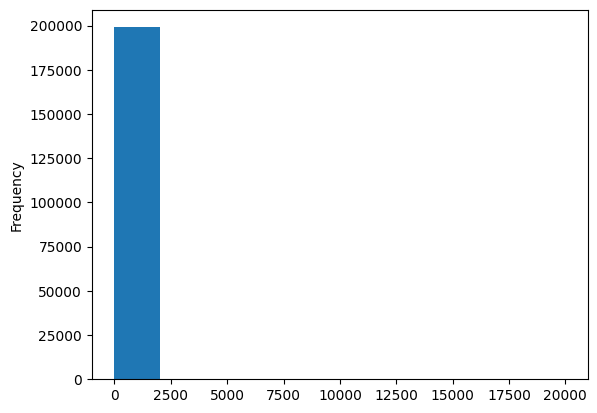

In [25]:
data['power'].plot.hist()

<AxesSubplot:ylabel='Frequency'>

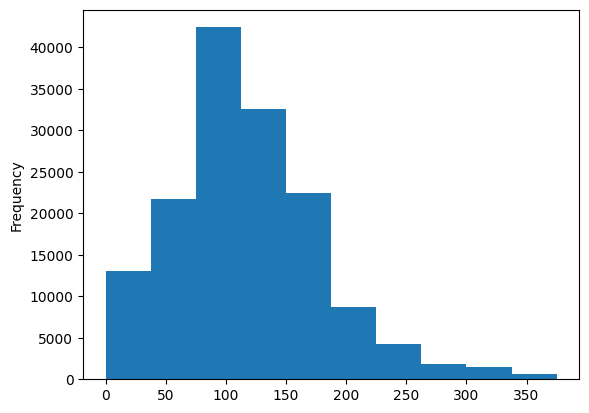

In [26]:
Train_data['power'].plot.hist()

<AxesSubplot:ylabel='Frequency'>

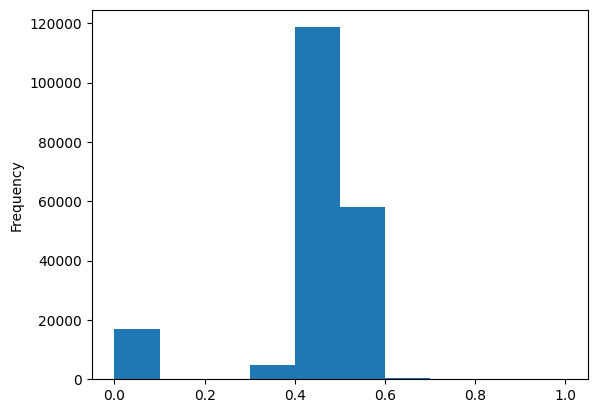

In [27]:
from sklearn import preprocessing
min_max_scaler = preprocessing.MinMaxScaler()
data['power'] = np.log(data['power'] + 1) 
data['power'] = ((data['power'] - np.min(data['power'])) / (np.max(data['power']) - np.min(data['power'])))
data['power'].plot.hist()

<AxesSubplot:ylabel='Frequency'>

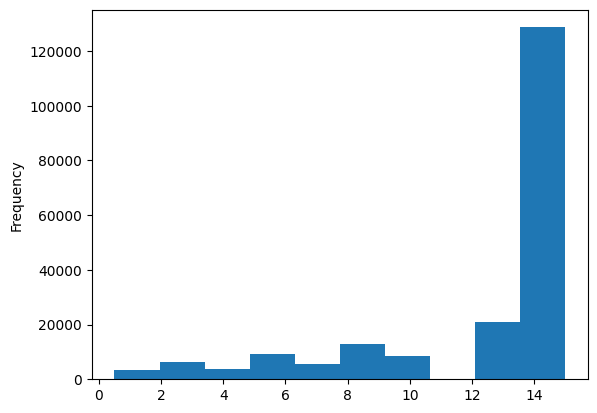

In [28]:
data['kilometer'].plot.hist()

<AxesSubplot:ylabel='Frequency'>

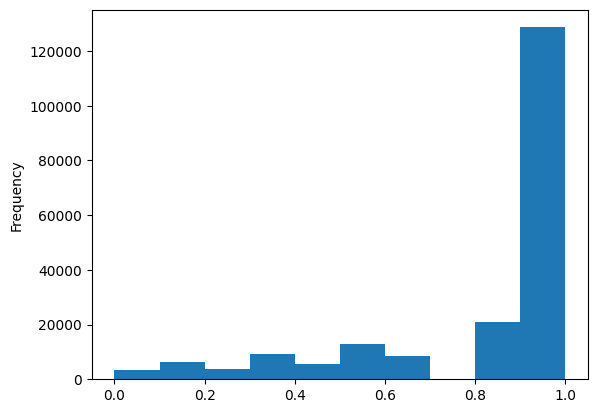

In [30]:
data['kilometer'] = ((data['kilometer'] - np.min(data['kilometer'])) / 
                        (np.max(data['kilometer']) - np.min(data['kilometer'])))
data['kilometer'].plot.hist()

In [31]:
def max_min(x):
    return (x - np.min(x)) / (np.max(x) - np.min(x))

data['brand_amount'] = ((data['brand_amount'] - np.min(data['brand_amount'])) / 
                        (np.max(data['brand_amount']) - np.min(data['brand_amount'])))
data['brand_price_average'] = ((data['brand_price_average'] - np.min(data['brand_price_average'])) / 
                               (np.max(data['brand_price_average']) - np.min(data['brand_price_average'])))
data['brand_price_max'] = ((data['brand_price_max'] - np.min(data['brand_price_max'])) / 
                           (np.max(data['brand_price_max']) - np.min(data['brand_price_max'])))
data['brand_price_median'] = ((data['brand_price_median'] - np.min(data['brand_price_median'])) /
                              (np.max(data['brand_price_median']) - np.min(data['brand_price_median'])))
data['brand_price_min'] = ((data['brand_price_min'] - np.min(data['brand_price_min'])) / 
                           (np.max(data['brand_price_min']) - np.min(data['brand_price_min'])))
data['brand_price_std'] = ((data['brand_price_std'] - np.min(data['brand_price_std'])) / 
                           (np.max(data['brand_price_std']) - np.min(data['brand_price_std'])))
data['brand_price_sum'] = ((data['brand_price_sum'] - np.min(data['brand_price_sum'])) / 
                           (np.max(data['brand_price_sum']) - np.min(data['brand_price_sum'])))

In [32]:
data = pd.get_dummies(data, columns=['model', 'brand', 'bodyType', 'fuelType',
 'gearbox', 'notRepairedDamage', 'power_bin'])

In [33]:
print(data.shape)
data.columns

(199037, 384)


Index(['SaleID', 'name', 'power', 'kilometer', 'seller', 'offerType', 'price',
       'v_0', 'v_1', 'v_2',
       ...
       'power_bin_20.0', 'power_bin_21.0', 'power_bin_22.0', 'power_bin_23.0',
       'power_bin_24.0', 'power_bin_25.0', 'power_bin_26.0', 'power_bin_27.0',
       'power_bin_28.0', 'power_bin_29.0'],
      dtype='object', length=384)

In [34]:
 # 这份数据可以给 LR 用
data.to_csv('data_for_lr.csv', index=0)

In [35]:
print(data['power'].corr(data['price'], method='spearman'))
print(data['kilometer'].corr(data['price'], method='spearman'))
print(data['brand_amount'].corr(data['price'], method='spearman'))
print(data['brand_price_average'].corr(data['price'], method='spearman'))
print(data['brand_price_max'].corr(data['price'], method='spearman'))
print(data['brand_price_median'].corr(data['price'], method='spearman'))

0.5728285196051496
-0.4082569701616764
-0.22421312026449425
0.22421312026449425
0.2044383343337497
0.22421312026449425


<AxesSubplot:title={'center':'Correlation of Numeric Features with Price'}>

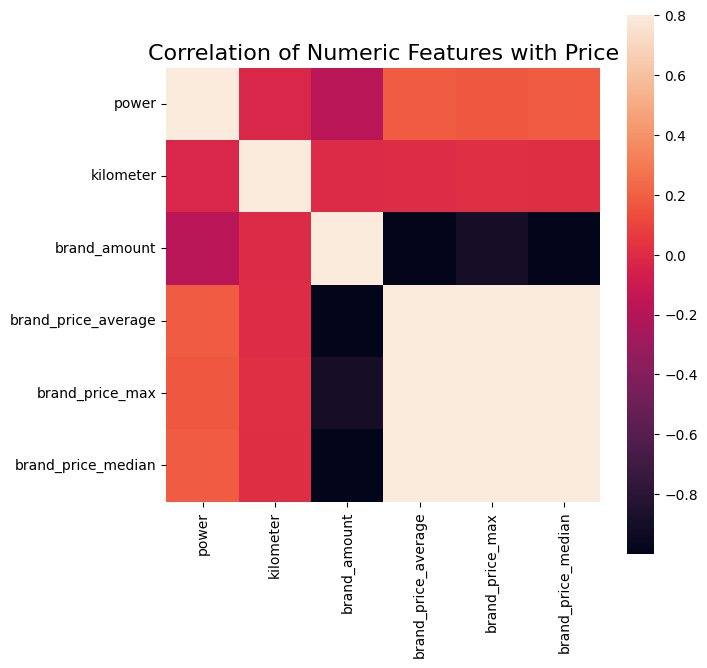

In [36]:
data_numeric = data[['power', 'kilometer', 'brand_amount', 'brand_price_average', 
                     'brand_price_max', 'brand_price_median']]
correlation = data_numeric.corr()
f , ax = plt.subplots(figsize = (7, 7))
plt.title('Correlation of Numeric Features with Price',y=1,size=16)
sns.heatmap(correlation,square = True,  vmax=0.8)